In [27]:
#Importando as bibliotecas
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt
import numpy as np
from sqlalchemy import create_engine

In [28]:
#Conectando ao banco de dados 
server = 'localhost'
database = 'olist'
engine = create_engine(f'mssql+pyodbc://@{server}/{database}?driver=ODBC+Driver+17+for+SQL+Server')

In [29]:
#Criando os DFs a partir das views do banco de dados 
views = [
    "vw_dim_customers", "vw_dim_orders", "vw_dim_product",
    "vw_dim_sellers", "vw_fact_order_items", "vw_fact_order_payments",
]

dfs = {v.replace("vw_", ""): pd.read_sql_table(v, engine) for v in views}
    
dfs["order_reviews"] = pd.read_sql("SELECT * FROM order_reviews", engine)

In [30]:
#Visualizando os dataframes
for nome, df in dfs.items():
    print(nome, list(df.columns))

dim_customers ['customer_id', 'customer_unique_id', 'customer_city', 'customer_state']
dim_orders ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
dim_product ['product_id', 'product_category_name']
dim_sellers ['seller_id', 'seller_city', 'seller_state']
fact_order_items ['order_id', 'order_item_id', 'product_id', 'seller_id', 'total_item_value', 'price', 'freight_value']
fact_order_payments ['order_id', 'payment_sequential', 'payment_type', 'payment_value']
order_reviews ['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']


In [31]:
#Verificando a composição dos DFs
for nome, df in dfs.items():
    print(nome, df.shape, df.isnull().sum().sum())

dim_customers (99441, 4) 0
dim_orders (99092, 8) 4739
dim_product (32951, 2) 0
dim_sellers (3095, 3) 0
fact_order_items (112650, 7) 0
fact_order_payments (103886, 4) 0
order_reviews (99224, 7) 145914


# Análise financeira: 
Objetivo tentar aumentar o faturamento 

In [32]:
dfs['fact_order_items'].head()

,order_id,order_item_id,product_id,seller_id,total_item_value,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,72.19,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,259.83,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,216.87,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,25.78,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,218.04,199.90,18.14


In [33]:
dfs['fact_order_payments'].head()

,order_id,payment_sequential,payment_type,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,128.45


# Decisão 
O Order_payments é usada para calcular o tipo de pagamento e se ele foi parcelado ou não enquanto o order_items calcula o preço de um produto e também temos o seu frete 

In [34]:
total_itens = dfs['fact_order_items']['total_item_value'].sum()
total_pagamentos = dfs['fact_order_payments']['payment_value'].sum()

print(f'Total itens (price + frete): {total_itens:,.2f}')
print(f'Total pagamentos: {total_pagamentos:,.2f}')
print(f'Diferença: {(total_pagamentos - total_itens) / total_itens:.2%}')

Total itens (price + frete): 15,843,553.24
Total pagamentos: 16,008,872.12
Diferença: 1.04%


In [35]:
dfs['fact_order_payments']['payment_value'].describe()

count    103886.000000
mean        154.100380
std         217.494064
min           0.000000
25%          56.790000
50%         100.000000
75%         171.837500
max       13664.080000
Name: payment_value, dtype: float64

In [36]:
dfs['fact_order_items']['freight_value'].describe()

count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
max         409.680000
Name: freight_value, dtype: float64

# Pareto entre categoria, estado e vendedor 


In [37]:
# 1. Juntar as tabelas
base = (
    dfs['fact_order_items']
    .merge(dfs['dim_product'], on='product_id', how='left')
    .merge(dfs['dim_sellers'], on='seller_id', how='left')
)

In [38]:
# 2. Função do Pareto + classe ABC
def pareto_abc(base, grupo, valor='price', corte_a=0.80, corte_b=0.95):
    tabela = (
        base.groupby(grupo)[valor]
        .sum()
        .sort_values(ascending=False)
        .reset_index()
        .rename(columns={valor: 'total'})
    )

    tabela['participacao'] = tabela['total'] / tabela['total'].sum()
    tabela['acumulado'] = tabela['participacao'].cumsum()
    tabela['acumulado_grupos'] = np.arange(1, len(tabela) + 1) / len(tabela)

    # Usa o acumulado ANTES do item: quem cruza o corte fica na classe anterior
    acumulado_anterior = tabela['acumulado'].shift(fill_value=0)
    tabela['classe'] = np.select(
        [acumulado_anterior < corte_a, acumulado_anterior < corte_b],
        ['A', 'B'],
        default='C'
    )
    return tabela

In [39]:
# 3. Calcular para as três dimensões
pareto_categoria = pareto_abc(base, 'product_category_name')
pareto_estado = pareto_abc(base, 'seller_state')
pareto_vendedor = pareto_abc(base, 'seller_id')

In [40]:
# 4. Resumo por classe
def resumo(tabela, nome):
    resultado = tabela.groupby('classe').agg(
        quantidade=('participacao', 'size'),
        receita=('participacao', 'sum')
    )
    resultado['pct_grupos'] = resultado['quantidade'] / resultado['quantidade'].sum()
    print(f'{nome}')
    print((resultado * 1).round(3), '\n')

resumo(pareto_categoria, 'Categorias')
resumo(pareto_estado, 'Estados')
resumo(pareto_vendedor, 'Vendedores')

Categorias
        quantidade  receita  pct_grupos
classe                                 
A               18    0.812       0.243
B               16    0.140       0.216
C               40    0.048       0.541 

Estados
        quantidade  receita  pct_grupos
classe                                 
A                3    0.811       0.130
B                4    0.157       0.174
C               16    0.031       0.696 

Vendedores
        quantidade  receita  pct_grupos
classe                                 
A              544     0.80       0.176
B              763     0.15       0.247
C             1788     0.05       0.578 



In [41]:
# 5. Quem forma os 80% (classe A)
def classe_a(tabela, grupo):
    return tabela[tabela['classe'] == 'A'][[grupo, 'total', 'participacao', 'acumulado']]


classe_a(pareto_vendedor, 'seller_id').head(20)  # são centenas, mostra só os 20 maiores

,seller_id,total,participacao,acumulado
0,4869f7a5dfa277a7dca6462dcf3b52b2,229472.63,0.016883,0.016883
1,53243585a1d6dc2643021fd1853d8905,222776.05,0.016391,0.033274
2,4a3ca9315b744ce9f8e9374361493884,200472.92,0.014750,0.048024
3,fa1c13f2614d7b5c4749cbc52fecda94,194042.03,0.014277,0.062300
4,7c67e1448b00f6e969d365cea6b010ab,187923.89,0.013826,0.076127
5,7e93a43ef30c4f03f38b393420bc753a,176431.87,0.012981,0.089108
6,da8622b14eb17ae2831f4ac5b9dab84a,160236.57,0.011789,0.100897
7,7a67c85e85bb2ce8582c35f2203ad736,141745.53,0.010429,0.111326
8,1025f0e2d44d7041d6cf58b6550e0bfa,138968.55,0.010225,0.121550
9,955fee9216a65b617aa5c0531780ce60,135171.70,0.009945,0.131496


In [42]:
classe_a(pareto_estado, 'seller_state')

,seller_state,total,participacao,acumulado
0,SP,8753396.21,0.644028,0.644028
1,PR,1261887.21,0.092843,0.736871
2,MG,1011564.74,0.074425,0.811296


In [43]:
classe_a(pareto_categoria, 'product_category_name')

,product_category_name,total,participacao,acumulado
0,beleza_saude,1258681.34,0.092607,0.092607
1,relogios_presentes,1205005.68,0.088658,0.181265
2,cama_mesa_banho,1036988.68,0.076296,0.257561
3,esporte_lazer,988048.97,0.072695,0.330256
4,informatica_acessorios,911954.32,0.067097,0.397353
5,moveis_decoracao,729762.49,0.053692,0.451045
6,cool_stuff,635290.85,0.046741,0.497786
7,utilidades_domesticas,632248.66,0.046517,0.544304
8,automotivo,592720.11,0.043609,0.587913
9,ferramentas_jardim,485256.46,0.035703,0.623615


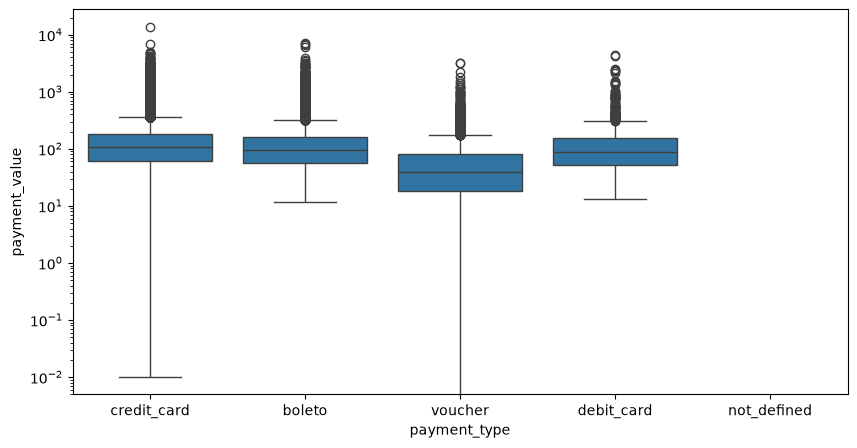

0.5807035695809623


In [ ]:
pagamentos = dfs["fact_order_payments"]

# Boxplot por tipo (escala log por causa dos outliers)
plt.figure(figsize=(10, 5))
sns.boxplot(data=pagamentos, x="payment_type", y="payment_value")
plt.yscale("log")
plt.show()

In [ ]:
# Participação no volume e no faturamento
resumo = pagamentos.groupby("payment_type")["payment_value"].agg(["count", "sum"])

resumo["% pagamentos"] = resumo["count"] / resumo["count"].sum() * 100
resumo["% faturamento"] = resumo["sum"] / resumo["sum"].sum() * 100

print(resumo.round(1).sort_values("sum", ascending=False))

              count         sum  % pagamentos  % faturamento
payment_type                                                
credit_card   76795  12542084.2          73.9           78.3
boleto        19784   2869361.3          19.0           17.9
voucher        5775    379436.9           5.6            2.4
debit_card     1529    217989.8           1.5            1.4
not_defined       3         0.0           0.0            0.0


In [71]:
# Voucher: complementar ou único meio?
ids_voucher = pagamentos.loc[pagamentos["payment_type"] == "voucher", "order_id"]
tipos_por_pedido = pagamentos[pagamentos["order_id"].isin(ids_voucher)].groupby("order_id")["payment_type"].nunique()
print(f"O voucher é complementar em {round((tipos_por_pedido > 1).mean(), 2) * 100:.1f}% dos casos.")

O voucher é complementar em 58.0% dos casos.


In [ ]:
# Vendas vem do mesmo estado do vendedor ou de outro estado?
base_mesmo_estado = (dfs["fact_order_items"]
               .merge(dfs["dim_orders"][["order_id", "customer_id", "order_status"]], on="order_id", how="left")
               .merge(dfs["dim_product"][["product_id", "product_category_name"]], on="product_id", how="left")
               .merge(dfs["dim_sellers"][["seller_id", "seller_state"]], on="seller_id", how="left")
               .merge(dfs["dim_customers"][["customer_id", "customer_state"]], on="customer_id", how="left"))
base_mesmo_estado = base_mesmo_estado[base_mesmo_estado["order_status"] != "canceled"]

# Oferta x demanda: valor vendido dentro do mesmo estado
fluxo = pd.crosstab(base_mesmo_estado["seller_state"], base_mesmo_estado["customer_state"],
                    values=base_mesmo_estado["price"], aggfunc="sum", normalize="all") * 100

mesmo_estado = sum(fluxo.loc[uf, uf] for uf in fluxo.index if uf in fluxo.columns)

print(f"Dentro do mesmo estado: {mesmo_estado:.1f}% | entre estados: {100 - mesmo_estado:.1f}%")

Dentro do mesmo estado: 31.2% | entre estados: 68.8%


In [82]:
colunas_data = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
                "order_delivered_customer_date", "order_estimated_delivery_date"]

pedidos = dfs["dim_orders"].copy()

base_pedidos = (dfs["fact_order_items"]
        .merge(pedidos[["order_id", "customer_id", "order_status"] + colunas_data], on="order_id", how="left")
        .merge(dfs["dim_product"][["product_id", "product_category_name"]], on="product_id", how="left")
        .merge(dfs["dim_sellers"][["seller_id", "seller_state"]], on="seller_id", how="left")
        .merge(dfs["dim_customers"][["customer_id", "customer_state"]], on="customer_id", how="left"))

#Tirando pedidos cancelados da base 
base_pedidos = base_pedidos[base_pedidos["order_status"] != "canceled"]

#Criando a coluna "rota" para indentificar se a venda é do mesmo estado do vendedor ou de outro estado
base_pedidos["rota"] = np.where(base_pedidos["seller_state"] == base_pedidos["customer_state"], "mesmo estado", "entre estados")

#Criando a base de entregas, com pedidos entregues e com data de entrega 
entrega = base[(base_pedidos["order_status"] == "delivered") & base_pedidos["order_delivered_customer_date"].notna()].copy()

#variavel para calcular os prazos de entrega 
compra = entrega["order_purchase_timestamp"]

#Calculando os prazos de entrega 
entrega["prazo_real"] = (entrega["order_delivered_customer_date"] - compra).dt.days
entrega["prazo_prometido"] = (entrega["order_estimated_delivery_date"] - compra).dt.days
entrega["dias_atraso"] = (entrega["order_delivered_customer_date"] - entrega["order_estimated_delivery_date"]).dt.days
entrega["atrasou"] = entrega["dias_atraso"] > 0
entrega["etapa_vendedor"] = (entrega["order_delivered_carrier_date"] - entrega["order_approved_at"]).dt.days
entrega["etapa_transporte"] = (entrega["order_delivered_customer_date"] - entrega["order_delivered_carrier_date"]).dt.days

# Janela do pico: definida olhando a tabela mensal, então é premissa declarada
entrega["pico"] = compra.between("2017-11-01", "2018-03-31")
entrega["mes"] = compra.dt.to_period("M")

entrega[["prazo_real", "prazo_prometido", "dias_atraso", "atrasou", "etapa_vendedor", "etapa_transporte", "pico", "mes"]].head()

,prazo_real,prazo_prometido,dias_atraso,atrasou,etapa_vendedor,etapa_transporte,pico,mes
0,7,16,-9,False,6.0,1.0,False,2017-09
1,16,19,-3,False,8.0,8.0,False,2017-04
2,8,22,-14,False,2.0,6.0,True,2018-01
3,6,12,-6,False,2.0,4.0,False,2018-08
4,25,41,-16,False,12.0,13.0,False,2017-02


In [ ]:
# Frete, prazo e atraso por estado do cliente
por_estado = entrega.groupby("customer_state").agg(
    itens=("price", "count"), preco=("price", "sum"), frete=("freight_value", "sum"),
    prazo_mediano=("prazo_real", "median"), media_atraso=("atrasou", "mean"))

por_estado["frete / preço (%)"] = por_estado["frete"] / por_estado["preco"] * 100
por_estado["media_atraso"] *= 100

print(por_estado.sort_values("preco", ascending=False).head(10).round(1))

                itens      preco     frete  prazo_mediano  media_atraso  \
customer_state                                                            
SP              46331  5054517.0  700297.9            7.0           4.4   
RJ              14097  1751433.8  294923.8           12.0          11.7   
MG              12877  1548206.9  265747.4           10.0           4.4   
RS               6116   726194.9  132185.8           13.0           5.9   
PR               5619   664048.0  115166.1           10.0           3.9   
SC               4084   504774.1   87853.0           13.0           8.2   
BA               3680   493339.3   97477.5           17.0          11.9   
DF               2347   295454.6   49468.6           11.0           6.0   
GO               2270   281932.2   51224.0           14.0           6.3   
ES               2222   267783.7   48882.5           13.0          10.8   

                frete / preço (%)  
customer_state                     
SP                         

In [ ]:
# Rota: mesma origem (SP), destinos diferentes

estados = ["SP", "MG", "PR", "RJ", "BA", "ES"]

origem_sp = entrega[(entrega["seller_state"] == "SP") & entrega["customer_state"].isin(estados)]
rotas = origem_sp.groupby("customer_state").agg(itens=("price", "count"), pct_atraso=("atrasou", "mean"))
rotas["pct_atraso"] *= 100
print(rotas.round(1))

                itens  pct_atraso
customer_state                   
BA               2623        12.8
ES               1620        12.2
MG               8544         5.0
PR               3594         4.3
RJ               9381        13.5
SP              35351         4.6


In [48]:
pedidos_rj = entrega[entrega["customer_state"] == "RJ"].copy()

# Mês a mês no RJ
mensal = pedidos_rj.groupby("mes").agg(itens=("price", "count"), pct_atraso=("atrasou", "mean"),
                                       prazo_prometido=("prazo_prometido", "median"),
                                       prazo_real=("prazo_real", "median"))
mensal["pct_atraso"] *= 100
print(mensal.round(1))

# Pico x fora do pico
pico = pedidos_rj.groupby("pico").agg(itens=("price", "count"), atrasados=("atrasou", "sum"))
pico["% dos atrasos"] = pico["atrasados"] / pico["atrasados"].sum() * 100
pico["% atraso"] = pico["atrasados"] / pico["itens"] * 100
print(pico.round(1))

# Simulação: e se somarmos N dias ao prazo prometido no pico?
no_pico = pedidos_rj[pedidos_rj["pico"]]
for extra in [0, 3, 5, 7, 10]:
    print(f"+{extra:>2} dias: {(no_pico['dias_atraso'] > extra).mean():.1%} de atraso")

# Teste do viés dos "68 vendedores": como eles atrasam fora do RJ?
por_vendedor = pedidos_rj.groupby("seller_id").agg(itens=("price", "count"), atrasados=("atrasou", "sum"))
principais = por_vendedor.sort_values("atrasados", ascending=False).head(68).index
fora_rj = entrega[entrega["customer_state"] != "RJ"]
print(fora_rj[fora_rj["seller_id"].isin(principais)]["atrasou"].mean(),
      fora_rj[~fora_rj["seller_id"].isin(principais)]["atrasou"].mean())

         itens  pct_atraso  prazo_prometido  prazo_real
mes                                                    
2017-01    103         2.9             40.0        11.0
2017-02    266         3.4             31.0        10.5
2017-03    418         3.8             23.5         9.5
2017-04    362         6.4             26.0        13.0
2017-05    542         2.4             24.0        10.0
2017-06    434         3.0             24.0        11.0
2017-07    622         2.7             24.0        11.0
2017-08    612         2.6             24.0        11.0
2017-09    685         5.3             22.0        11.0
2017-10    759         6.1             23.0        11.0
2017-11   1184        24.9             23.0        15.0
2017-12    835        24.0             28.0        19.0
2018-01    977        13.1             29.0        15.0
2018-02   1015        33.2             24.0        19.0
2018-03    996        32.0             28.0        20.0
2018-04    936         4.3             32.0     

In [49]:
# Taxa "normal" de cada estado = taxa fora do pico
taxa_normal = entrega[~entrega["pico"]].groupby("customer_state")["atrasou"].mean()

durante_pico = entrega[entrega["pico"]].copy()
durante_pico["esperado"] = durante_pico["customer_state"].map(taxa_normal)

resultado = durante_pico.groupby("customer_state").agg(
    itens=("price", "count"), atrasados=("atrasou", "sum"),
    esperado=("esperado", "sum"), vendas=("price", "sum"))
resultado["atrasos_a_mais"] = resultado["atrasados"] - resultado["esperado"]
resultado["vendas_associadas"] = resultado["atrasos_a_mais"] / resultado["itens"] * resultado["vendas"]

print(resultado.sort_values("vendas_associadas", ascending=False).head(10).round(0))
print(f"Total: {resultado['atrasos_a_mais'].sum():,.0f} itens | R$ {resultado['vendas_associadas'].sum():,.0f}")

                itens  atrasados  esperado     vendas  atrasos_a_mais  \
customer_state                                                          
RJ               5007       1279     201.0   600891.0          1078.0   
SP              15764        939     567.0  1679100.0           372.0   
MG               4677        386     102.0   558987.0           284.0   
RS               2083        259      51.0   248011.0           208.0   
SC               1479        211      70.0   167485.0           141.0   
CE                505        137      31.0    68744.0           106.0   
BA               1279        216     118.0   159563.0            98.0   
PR               1947        143      40.0   214380.0           103.0   
ES                774        140      53.0    90311.0            87.0   
MA                289         93      29.0    41927.0            64.0   

                vendas_associadas  
customer_state                     
RJ                       129365.0  
SP             